# Modelagem preditiva da produtividade da safra de soja com uso de aprendizado de máquina e dados agrometeorológicos — Modelagem (Etapa 2: clima por subperíodo)

**Integrantes:**
**Orientador:**

**Síntese do conteúdo deste arquivo:** a Etapa 1 (`modelagem.ipynb`) mostrou que o clima resumido em um único total de chuva e uma temperatura média da safra (out–mar) não distingue safras como 2021 (recorde) e 2022 (seca). Este notebook recalcula o clima a partir dos dados **diários** do INMET já baixados, dividindo a safra em subperíodos do ciclo da soja (out–nov, dez–fev, mar, abr–mai) e criando indicadores de estresse no período crítico (dias secos consecutivos, dias de calor, temperatura máxima e umidade mínima em dez–fev). Treina regressão linear (OLS), Random Forest e Gradient Boosting (estes dois prevendo o desvio em relação à tendência) em duas versões: **previsão de março** (só com dados disponíveis até fevereiro, uso real) e **com colheita** (inclui chuva de abr–mai, explicativa). Avalia com o mesmo corte temporal da Etapa 1 (teste 2021–2025) e com validação "deixa uma safra de fora" (*leave-one-year-out*), comparando sempre com o melhor modelo da Etapa 1 nas mesmas linhas. As variáveis climáticas por subperíodo são salvas em `dataset/processed/clima_subperiodos_estacao_safra.csv`.

| Data       | Autor           | Descrição                                                                 |
|------------|-----------------|-----------------------------------------------------------------------------|
| 2026-10-22 |                 | Criação do notebook — variáveis climáticas por subperíodo a partir do INMET diário, modelos de março e com colheita, validação temporal e leave-one-year-out |

## 1. Imports e configuração

Mesmas convenções da Etapa 1: executado a partir de `notebooks/`, com a mesma semente
e o mesmo corte temporal.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

RAW = "../dataset/raw"
PROCESSED = "../dataset/processed"

ANO_CORTE = 2020          # treino: safras <= 2020 | teste: safras 2021-2025
SEED = 42
COBERTURA_MINIMA = 0.8    # fração mínima de dias com dado em cada subperíodo
LIMIAR_SECO_MM = 1.0      # dia seco: chuva < 1 mm
LIMIAR_CALOR_C = 32.0     # dia de calor: temperatura máxima >= 32 °C

pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
print("Ambiente pronto.")

Ambiente pronto.


## 2. Painel município–safra

O mesmo painel da Etapa 1. Cada município está ligado a **uma** estação INMET (a mais
próxima, coluna `codigo_estacao`), e é por essa estação que as novas variáveis
climáticas serão juntadas.

In [2]:
painel = pd.read_csv(f"{PROCESSED}/painel_municipio_safra.csv")
coords = (pd.read_csv(f"{RAW}/municipios_brasil_coords.csv",
                      usecols=["codigo_ibge", "latitude", "longitude"])
          .rename(columns={"codigo_ibge": "codigo_ibge_municipio"}))
painel = painel.merge(coords, on="codigo_ibge_municipio", how="left")

ALVO = "rendimento_kg_ha"
CHUVA = "precipitacao_total_safra_mm"
TEMP = "temperatura_media_safra_c"
ONI = "oni_media_safra"

com_rendimento = painel.dropna(subset=[ALVO])
print(f"Linhas com rendimento: {len(com_rendimento)} | "
      f"municípios: {com_rendimento['codigo_ibge_municipio'].nunique()}")

Linhas com rendimento: 10540 | municípios: 454


## 3. Clima diário do INMET → variáveis por subperíodo

A safra de soja no RS vai do plantio (out–nov) à colheita (abr–mai). Cada dia é
atribuído a uma safra (out–dez contam para a safra do ano seguinte) e a um subperíodo:

| Subperíodo | Fase da soja | Disponível para prever em março? |
|---|---|---|
| out–nov | semeadura e emergência | sim |
| dez–fev | floração e enchimento de grãos (**período crítico**) | sim |
| mar | fim do enchimento / maturação | parcialmente (início de março) |
| abr–mai | colheita | **não** — só serve para explicar a safra depois |

Variáveis criadas por estação e safra:

- `chuva_out_nov`, `chuva_dez_fev`, `chuva_mar`, `chuva_abr_mai`: chuva acumulada (mm);
- `seca_max_dez_fev`: maior sequência de dias secos (< 1 mm) em dez–fev;
- `dias_calor_dez_fev`: número de dias com máxima ≥ 32 °C em dez–fev;
- `tmax_dez_fev`: média da temperatura máxima diária em dez–fev (°C);
- `urmin_dez_fev`: média da umidade relativa mínima diária em dez–fev (%).

**Controle de qualidade:** o arquivo do INMET não tem uma linha para todo dia (falhas e
estações em pane). Antes de agregar, o calendário de cada estação é completado com os
dias faltantes como ausentes. Uma variável só é calculada se a estação tiver dado em
pelo menos 80% dos dias do subperíodo; caso contrário fica ausente — uma soma de chuva
com dias faltando pareceria uma seca que não existiu.

O arquivo mistura separadores decimais (a umidade mínima usa ponto, as demais colunas
vírgula), então todos os valores são convertidos trocando vírgula por ponto.

A tabela resultante (estação × safra) é salva em
`dataset/processed/clima_subperiodos_estacao_safra.csv` para ser reutilizada na Etapa 3.

In [3]:
colunas = {"Codigo Estacao": "estacao", "Data Medicao": "data",
           "PRECIPITACAO TOTAL, DIARIO (AUT)(mm)": "chuva",
           "TEMPERATURA MAXIMA, DIARIA (AUT)(°C)": "tmax",
           "UMIDADE RELATIVA DO AR, MINIMA DIARIA (AUT)(%)": "urmin"}
diario = (pd.read_csv(f"{RAW}/inmet_estacoes_RS_consolidado_2000_2025.csv", sep=";",
                      dtype=str, usecols=list(colunas))
          .rename(columns=colunas))
diario["data"] = pd.to_datetime(diario["data"])
for c in ["chuva", "tmax", "urmin"]:
    diario[c] = pd.to_numeric(diario[c].str.replace(",", "."), errors="coerce")
diario = diario.drop_duplicates(["estacao", "data"])

# Completa o calendário de cada estação: dia sem linha vira dia sem dado (NaN)
calendario = pd.MultiIndex.from_product(
    [diario["estacao"].unique(), pd.date_range("2000-01-01", "2025-12-31")],
    names=["estacao", "data"])
diario = diario.set_index(["estacao", "data"]).reindex(calendario).reset_index()

mes = diario["data"].dt.month
diario["ano_safra"] = diario["data"].dt.year + (mes >= 10)
diario["subperiodo"] = pd.cut(mes.where(mes >= 4, mes + 12), bins=[3, 5, 9, 11, 14, 15],
                              labels=["abr_mai", "fora", "out_nov", "dez_fev", "mar"])
diario = diario[(diario["subperiodo"] != "fora") & diario["ano_safra"].between(2001, 2025)]
print(f"Dias-estação na janela out–mai: {len(diario):,}")
print(diario[["chuva", "tmax", "urmin"]].describe().round(1))

Dias-estação na janela out–mai: 273,645
           chuva       tmax      urmin
count 166,377.00 171,479.00 171,823.00
mean        4.60      26.50      50.80
std        12.40       5.00      17.00
min         0.00       4.90       7.00
25%         0.00      23.20      38.00
50%         0.00      26.70      50.00
75%         1.80      30.00      63.00
max       249.40      43.80     100.00


In [4]:
chave = ["estacao", "ano_safra", "subperiodo"]
g = diario.groupby(chave, observed=True)
sub = pd.DataFrame({
    "chuva": g["chuva"].sum(min_count=1),
    "cob_chuva": g["chuva"].count() / g.size(),
    "tmax": g["tmax"].mean(),
    "cob_tmax": g["tmax"].count() / g.size(),
    "urmin": g["urmin"].mean(),
    "cob_urmin": g["urmin"].count() / g.size(),
    "dias_calor": g["tmax"].apply(lambda s: (s >= LIMIAR_CALOR_C).sum()),
})

# Maior sequência de dias secos: cada dia não seco (ou sem dado) inicia um novo bloco
seco = diario["chuva"] < LIMIAR_SECO_MM
bloco = (~seco).groupby([diario["estacao"], diario["ano_safra"], diario["subperiodo"]],
                        observed=True).cumsum()
sub["seca_max"] = (seco.groupby([diario["estacao"], diario["ano_safra"],
                                 diario["subperiodo"], bloco], observed=True).sum()
                   .groupby(level=[0, 1, 2], observed=True).max())

# Aplica a cobertura mínima
for var, cob in [("chuva", "cob_chuva"), ("seca_max", "cob_chuva"),
                 ("tmax", "cob_tmax"), ("dias_calor", "cob_tmax"), ("urmin", "cob_urmin")]:
    sub.loc[sub[cob] < COBERTURA_MINIMA, var] = np.nan

wide = sub[["chuva"]].unstack("subperiodo")
wide.columns = [f"chuva_{s}" for s in wide.columns.get_level_values(1)]
dez_fev = sub.xs("dez_fev", level="subperiodo")[["seca_max", "dias_calor", "tmax", "urmin"]]
dez_fev.columns = [f"{c}_dez_fev" for c in dez_fev.columns]
clima_sub = wide.join(dez_fev).reset_index().rename(columns={"estacao": "codigo_estacao"})

NOVAS = ["chuva_out_nov", "chuva_dez_fev", "chuva_mar", "chuva_abr_mai",
         "seca_max_dez_fev", "dias_calor_dez_fev", "tmax_dez_fev", "urmin_dez_fev"]
print(f"Estação × safra: {len(clima_sub)}")
print("Fração ausente por variável (cobertura < 80%):")
print(clima_sub[NOVAS].isna().mean().round(2).to_string())

# Salvo para reutilização na Etapa 3 (modelagem_etapa3.ipynb)
clima_sub.to_csv(f"{PROCESSED}/clima_subperiodos_estacao_safra.csv", index=False)
print(f"\nSalvo em {PROCESSED}/clima_subperiodos_estacao_safra.csv")

Estação × safra: 1125
Fração ausente por variável (cobertura < 80%):
chuva_out_nov        0.42
chuva_dez_fev        0.41
chuva_mar            0.40
chuva_abr_mai        0.43
seca_max_dez_fev     0.41
dias_calor_dez_fev   0.39
tmax_dez_fev         0.39
urmin_dez_fev        0.38

Salvo em ../dataset/processed/clima_subperiodos_estacao_safra.csv


## 4. Junção ao painel e base de modelagem

Para que todas as comparações sejam justas, a base de modelagem tem só as linhas em que
**todas** as variáveis existem — as da Etapa 1 (chuva total e temperatura média) e as
novas. Assim, o melhor modelo da Etapa 1 é avaliado exatamente nas mesmas linhas que os
modelos novos.

In [5]:
painel_sub = painel.merge(clima_sub, on=["codigo_estacao", "ano_safra"], how="left")
base = painel_sub.dropna(subset=[ALVO, CHUVA, TEMP, ONI] + NOVAS).copy()

etapa1 = painel.dropna(subset=[ALVO, CHUVA, TEMP])
print(f"Linhas na base da Etapa 1: {len(etapa1)}")
print(f"Linhas na base da Etapa 2: {len(base)} "
      f"({len(base) / len(etapa1):.0%} da Etapa 1) | municípios: {base['codigo_ibge_municipio'].nunique()}")
print(f"  treino (<= {ANO_CORTE}): {(base['ano_safra'] <= ANO_CORTE).sum()} | "
      f"teste (> {ANO_CORTE}): {(base['ano_safra'] > ANO_CORTE).sum()}")

Linhas na base da Etapa 1: 5869
Linhas na base da Etapa 2: 4859 (83% da Etapa 1) | municípios: 446
  treino (<= 2020): 3372 | teste (> 2020): 1487


### As novas variáveis separam as safras?

Média por safra (entre as linhas da base). Compare 2021 × 2022: chuva total parecida,
mas chuva, seca e calor em dez–fev bem diferentes.

In [6]:
por_ano = base.groupby("ano_safra")[[ALVO, CHUVA] + NOVAS].mean()
por_ano.insert(0, "linhas", base.groupby("ano_safra").size())
por_ano.loc[2008:].round(0)

,linhas,rendimento_kg_ha,precipitacao_total_safra_mm,chuva_out_nov,chuva_dez_fev,chuva_mar,chuva_abr_mai,seca_max_dez_fev,dias_calor_dez_fev,tmax_dez_fev,urmin_dez_fev
ano_safra,,,,,,,,,,,
2008,179,"2,093.00",701.00,287.00,314.00,100.00,282.00,13.00,18.00,29.00,43.00
2009,272,"2,011.00",814.00,398.00,355.00,60.00,163.00,10.00,17.00,29.00,45.00
2010,296,"2,515.00","1,140.00",506.00,545.00,89.00,298.00,9.00,19.00,29.00,53.00
2011,267,"2,838.00",864.00,178.00,534.00,152.00,227.00,8.00,13.00,29.00,52.00
2012,161,"1,750.00",541.00,247.00,226.00,68.00,119.00,14.00,27.00,30.00,41.00
2013,299,"2,638.00",990.00,307.00,497.00,186.00,250.00,10.00,19.00,29.00,49.00
2014,220,"2,659.00",996.00,342.00,470.00,185.00,307.00,14.00,33.00,30.00,47.00
2015,152,"2,865.00",871.00,306.00,493.00,72.00,284.00,15.00,14.00,29.00,54.00
2016,190,"2,843.00","1,327.00",469.00,609.00,249.00,263.00,16.00,18.00,29.00,56.00


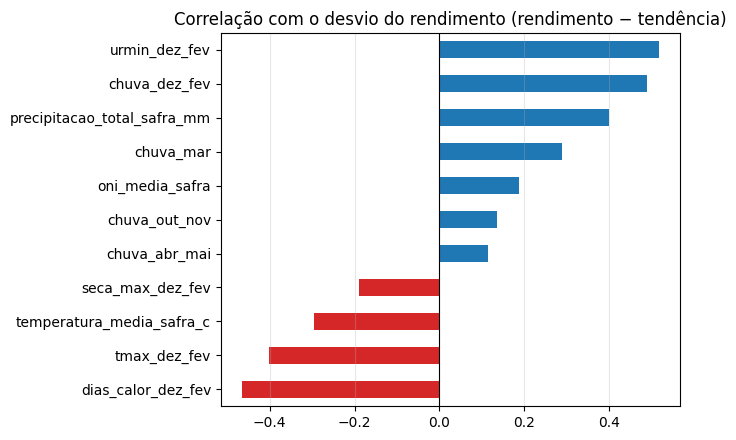

,correlação com o desvio do rendimento
dias_calor_dez_fev,-0.47
tmax_dez_fev,-0.40
temperatura_media_safra_c,-0.30
seca_max_dez_fev,-0.19
chuva_abr_mai,0.11
chuva_out_nov,0.14
oni_media_safra,0.19
chuva_mar,0.29
precipitacao_total_safra_mm,0.40
chuva_dez_fev,0.49


In [7]:
# Correlação de cada variável com o desvio do rendimento em relação à tendência estadual
tend_exp = LinearRegression().fit(com_rendimento[["ano_safra"]], com_rendimento[ALVO])
desvio = base[ALVO] - tend_exp.predict(base[["ano_safra"]])
correl = (base[[CHUVA, TEMP, ONI] + NOVAS].corrwith(desvio)
          .sort_values().rename("correlação com o desvio do rendimento"))
ax = correl.plot.barh(figsize=(7, 4.5), color=np.where(correl > 0, "tab:blue", "tab:red"))
ax.axvline(0, color="k", lw=0.8)
ax.set_title("Correlação com o desvio do rendimento (rendimento − tendência)")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()
correl.round(2).to_frame()

## 5. Modelos

Variáveis derivadas, calculadas **só com os anos de treino** (mesma lógica da Etapa 1):
tendência estadual, efeito do município (leave-one-out no treino) e chuva centrada na
média do treino para os termos quadráticos. As chuvas entram na OLS em centenas de mm,
para os coeficientes ficarem legíveis ("efeito de +100 mm").

| Modelo | Tipo | Variáveis |
|---|---|---|
| **E1 — OLS Etapa 1** | referência | ano, chuva total, chuva total², temperatura média, ONI |
| **A — OLS março** | regressão linear | ano, efeito do município, chuva out–nov, chuva dez–fev, chuva dez–fev², chuva mar, seca máx. dez–fev, dias de calor dez–fev, tmax dez–fev, umidade mín. dez–fev, ONI |
| **B — Gradient Boosting março** | árvores, prevê o desvio | efeito do município + as mesmas variáveis climáticas de A (sem termos quadráticos) |
| **C — Random Forest março** | árvores, prevê o desvio | as mesmas de B |
| **A+ / B+ — com colheita** | como A / B | + chuva abr–mai |

**Por que as árvores preveem o desvio:** na Etapa 1, Random Forest e Gradient Boosting
não conseguiam extrapolar o ano (para eles, toda safra após 2020 "era 2020"). Agora
eles aprendem só o **desvio** = rendimento − (tendência + efeito do município), isto é,
quanto o clima tirou ou somou em relação ao esperado. A previsão final é
tendência + efeito do município + desvio previsto. Latitude/longitude saíram: na
Etapa 1 elas dominaram as árvores sem ajudar a prever safras novas.

Os modelos "março" usam só dados disponíveis até o fim de fevereiro (mais `chuva_mar`,
que fica disponível no fim de março) — é a previsão de uso real, 1 a 2 meses antes da
colheita. Os modelos "com colheita" (A+, B+) não servem para prever, servem para medir
quanto do erro vem de eventos na colheita (como as enchentes de 2024).

In [8]:
def preparar(tr, te, anos_historico):
    # Tendência e efeito do município calculados só com os anos de treino
    historico = com_rendimento[com_rendimento["ano_safra"].isin(anos_historico)].copy()
    tendencia = LinearRegression().fit(historico[["ano_safra"]], historico[ALVO])
    historico["residuo"] = historico[ALVO] - tendencia.predict(historico[["ano_safra"]])
    efeito = historico.groupby("codigo_ibge_municipio")["residuo"].agg(["sum", "count"])
    medias = {c: tr[c].mean() for c in [CHUVA, "chuva_dez_fev"]}

    def derivar(d, eh_treino):
        d = d.copy()
        d["tendencia_kg_ha"] = tendencia.predict(d[["ano_safra"]])
        e = d[["codigo_ibge_municipio"]].join(efeito, on="codigo_ibge_municipio")
        soma, n = e["sum"].fillna(0), e["count"].fillna(0)
        if eh_treino:
            soma, n = soma - (d[ALVO] - d["tendencia_kg_ha"]), n - 1
        d["efeito_municipio"] = np.where(n > 0, soma / n.where(n > 0, 1), 0.0)
        d["base_kg_ha"] = d["tendencia_kg_ha"] + d["efeito_municipio"]
        d["chuva_c100"] = (d[CHUVA] - medias[CHUVA]) / 100
        d["chuva_c100_2"] = d["chuva_c100"] ** 2
        d["chuva_dez_fev_c100"] = (d["chuva_dez_fev"] - medias["chuva_dez_fev"]) / 100
        d["chuva_dez_fev_c100_2"] = d["chuva_dez_fev_c100"] ** 2
        for s in ["out_nov", "mar", "abr_mai"]:
            d[f"chuva_{s}_100"] = d[f"chuva_{s}"] / 100
        return d

    return derivar(tr, True), derivar(te, False)


ESTRESSE = ["seca_max_dez_fev", "dias_calor_dez_fev", "tmax_dez_fev", "urmin_dez_fev", ONI]
FEAT_E1 = ["ano_safra", "chuva_c100", "chuva_c100_2", TEMP, ONI]
FEAT_A = (["ano_safra", "efeito_municipio", "chuva_out_nov_100", "chuva_dez_fev_c100",
           "chuva_dez_fev_c100_2", "chuva_mar_100"] + ESTRESSE)
FEAT_B = ["efeito_municipio", "chuva_out_nov", "chuva_dez_fev", "chuva_mar"] + ESTRESSE


def gb():
    return HistGradientBoostingRegressor(learning_rate=0.05, max_iter=500, min_samples_leaf=20,
                                         early_stopping=True, validation_fraction=0.1,
                                         random_state=SEED)


def rf():
    return RandomForestRegressor(n_estimators=500, min_samples_leaf=5, n_jobs=-1, random_state=SEED)


# nome: (prevê o desvio?, variáveis, fábrica do estimador)
MODELOS = {
    "E1 - OLS Etapa 1": (False, FEAT_E1, LinearRegression),
    "A - OLS março": (False, FEAT_A, LinearRegression),
    "B - Gradient Boosting março": (True, FEAT_B, gb),
    "C - Random Forest março": (True, FEAT_B, rf),
    "A+ - OLS com colheita": (False, FEAT_A + ["chuva_abr_mai_100"], LinearRegression),
    "B+ - Gradient Boosting com colheita": (True, FEAT_B + ["chuva_abr_mai"], gb),
}


def ajustar_prever(nome, tr, te):
    desvio, feats, fabrica = MODELOS[nome]
    modelo = fabrica()
    if desvio:
        modelo.fit(tr[feats], tr[ALVO] - tr["base_kg_ha"])
        return te["base_kg_ha"].to_numpy() + modelo.predict(te[feats]), modelo
    modelo.fit(tr[feats], tr[ALVO])
    return modelo.predict(te[feats]), modelo


def metricas(y, pred):
    return {"RMSE (kg/ha)": mean_squared_error(y, pred) ** 0.5,
            "MAE (kg/ha)": mean_absolute_error(y, pred),
            "R²": r2_score(y, pred),
            "Viés (kg/ha)": np.mean(pred - y)}   # > 0: o modelo superestima


FORMATO = {"RMSE (kg/ha)": "{:.0f}", "MAE (kg/ha)": "{:.0f}", "R²": "{:.3f}",
           "Viés (kg/ha)": "{:+.0f}", "RMSE vs E1": "{:+.1%}"}
print("Modelos definidos:", ", ".join(MODELOS))

Modelos definidos: E1 - OLS Etapa 1, A - OLS março, B - Gradient Boosting março, C - Random Forest março, A+ - OLS com colheita, B+ - Gradient Boosting com colheita


## 6. Validação 1 — mesmo corte temporal da Etapa 1 (treino 2000–2020, teste 2021–2025)

In [9]:
treino, teste = preparar(base[base["ano_safra"] <= ANO_CORTE],
                         base[base["ano_safra"] > ANO_CORTE],
                         anos_historico=range(2000, ANO_CORTE + 1))
y_teste = teste[ALVO]
previsoes, ajustados = {}, {}
for nome in MODELOS:
    previsoes[nome], ajustados[nome] = ajustar_prever(nome, treino, teste)

corte = pd.DataFrame({n: metricas(y_teste, p) for n, p in previsoes.items()}).T
corte["RMSE vs E1"] = corte["RMSE (kg/ha)"] / corte.loc["E1 - OLS Etapa 1", "RMSE (kg/ha)"] - 1
print(f"Teste: {len(teste)} linhas | rendimento médio {y_teste.mean():.0f} kg/ha "
      f"(desvio-padrão {y_teste.std():.0f})")
corte.style.format(FORMATO)

Teste: 1487 linhas | rendimento médio 2524 kg/ha (desvio-padrão 884)


,RMSE (kg/ha),MAE (kg/ha),R²,Viés (kg/ha),RMSE vs E1
E1 - OLS Etapa 1,815,667,0.151,+216,+0.0%
A - OLS março,852,681,0.071,+511,+4.6%
B - Gradient Boosting março,1015,815,-0.320,+717,+24.6%
C - Random Forest março,1013,805,-0.313,+700,+24.3%
A+ - OLS com colheita,955,763,-0.168,+597,+17.3%
B+ - Gradient Boosting com colheita,1028,832,-0.352,+747,+26.2%


### Rendimento médio por safra de teste — observado × previsto

Rendimento médio por safra (kg/ha):


,rendimento_kg_ha,E1 - OLS Etapa 1,A - OLS março,B - Gradient Boosting março,C - Random Forest março,A+ - OLS com colheita,B+ - Gradient Boosting com colheita
ano_safra,,,,,,,
2021,"3,329.00","2,672.00","3,239.00","3,314.00","3,305.00","3,152.00","3,363.00"
2022,"1,684.00","2,524.00","2,754.00","2,600.00","2,492.00","2,948.00","2,531.00"
2023,"2,089.00","2,418.00","2,667.00","3,140.00","3,117.00","2,690.00","3,099.00"
2024,"2,949.00","3,256.00","3,422.00","3,591.00","3,590.00","3,741.00","3,787.00"
2025,"2,281.00","2,737.00","3,006.00","3,287.00","3,304.00","3,005.00","3,256.00"


RMSE por safra (kg/ha):


,E1 - OLS Etapa 1,A - OLS março,B - Gradient Boosting março,C - Random Forest março,A+ - OLS com colheita,B+ - Gradient Boosting com colheita
ano_safra,,,,,,
2021,801.00,416.00,381.00,355.00,429.00,376.00
2022,"1,100.00","1,250.00","1,081.00",990.00,"1,437.00","1,010.00"
2023,731.00,837.00,"1,255.00","1,258.00",853.00,"1,225.00"
2024,783.00,792.00,886.00,904.00,"1,056.00","1,044.00"
2025,749.00,948.00,"1,205.00","1,230.00",958.00,"1,190.00"


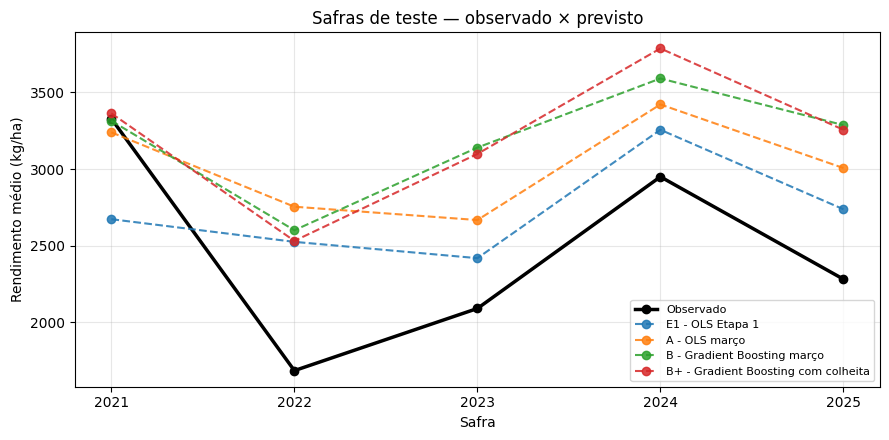

In [10]:
por_safra = teste[["ano_safra", ALVO]].assign(**previsoes).groupby("ano_safra").mean()
rmse_safra = pd.DataFrame({
    n: teste.assign(_p=p).groupby("ano_safra")
            .apply(lambda g: mean_squared_error(g[ALVO], g["_p"]) ** 0.5)
    for n, p in previsoes.items()})
print("Rendimento médio por safra (kg/ha):")
display(por_safra.round(0))
print("RMSE por safra (kg/ha):")
display(rmse_safra.round(0))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(por_safra.index, por_safra[ALVO], "k-o", lw=2.5, label="Observado")
for nome in ["E1 - OLS Etapa 1", "A - OLS março", "B - Gradient Boosting março",
             "B+ - Gradient Boosting com colheita"]:
    ax.plot(por_safra.index, por_safra[nome], "--o", alpha=0.85, label=nome)
ax.set_xticks(por_safra.index)
ax.set_xlabel("Safra")
ax.set_ylabel("Rendimento médio (kg/ha)")
ax.set_title("Safras de teste — observado × previsto")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 7. O que a OLS de março aprendeu (coeficientes)

Mesma ressalva da Etapa 1: os p-valores assumem erros independentes, mas linhas da mesma
safra são correlacionadas, então eles tendem a ser otimistas. Usar como indicação de
sinal e magnitude.

In [11]:
def tabela_ols(modelo, X, y):
    Xc = np.column_stack([np.ones(len(X)), X.to_numpy(dtype=float)])
    beta = np.r_[modelo.intercept_, modelo.coef_]
    residuos = y.to_numpy() - Xc @ beta
    gl = len(y) - Xc.shape[1]
    ep = np.sqrt(np.diag(residuos @ residuos / gl * np.linalg.inv(Xc.T @ Xc)))
    t = beta / ep
    return pd.DataFrame({"coeficiente": beta, "erro_padrao": ep, "t": t,
                         "p_valor": 2 * stats.t.sf(np.abs(t), gl)},
                        index=["intercepto"] + list(X.columns))


tabela_ols(ajustados["A - OLS março"], treino[FEAT_A], treino[ALVO])

,coeficiente,erro_padrao,t,p_valor
intercepto,"-136,760.88","5,221.29",-26.19,0.00
ano_safra,65.51,2.54,25.74,0.00
efeito_municipio,0.79,0.03,30.79,0.00
chuva_out_nov_100,-26.71,6.82,-3.91,0.00
chuva_dez_fev_c100,134.05,7.58,17.68,0.00
chuva_dez_fev_c100_2,-31.64,2.30,-13.78,0.00
chuva_mar_100,197.57,12.43,15.89,0.00
seca_max_dez_fev,-2.34,2.13,-1.10,0.27
dias_calor_dez_fev,-18.18,1.58,-11.49,0.00
tmax_dez_fev,205.49,14.84,13.85,0.00


**Como ler:** `chuva_*_100` é o efeito de +100 mm no subperíodo; `chuva_dez_fev_c100` é
medido a partir da chuva média de dez–fev no treino e `chuva_dez_fev_c100_2` negativo
indica que o ganho diminui quando a chuva é excessiva; `seca_max_dez_fev` é o efeito de
cada dia a mais na maior sequência seca; `dias_calor_dez_fev` de cada dia a mais com
máxima ≥ 32 °C; `tmax_dez_fev` de +1 °C na máxima média; `urmin_dez_fev` de +1 ponto
percentual na umidade mínima. Como várias dessas variáveis medem a mesma seca por
ângulos diferentes (correlacionadas entre si), um coeficiente isolado pode ficar menor
ou até trocar de sinal — o conjunto é que deve ser interpretado.

## 8. Importância das variáveis — Gradient Boosting de março

Importância por permutação nas safras de teste (quanto o RMSE piora ao embaralhar cada
variável).

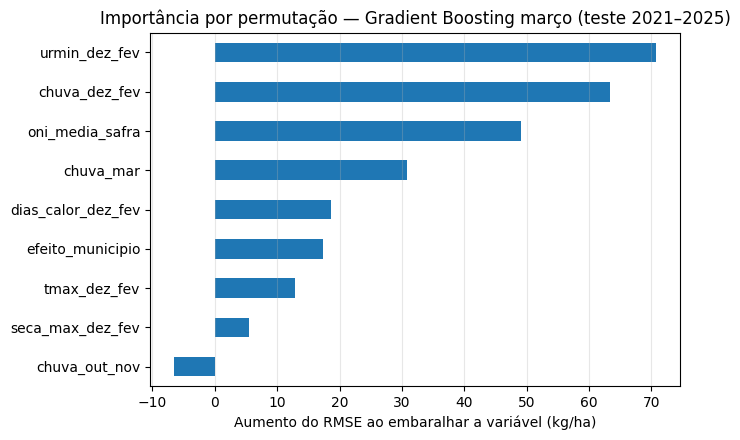

,aumento do RMSE (kg/ha)
urmin_dez_fev,71.00
chuva_dez_fev,63.00
oni_media_safra,49.00
chuva_mar,31.00
dias_calor_dez_fev,19.00
efeito_municipio,17.00
tmax_dez_fev,13.00
seca_max_dez_fev,5.00
chuva_out_nov,-7.00


In [12]:
r = permutation_importance(ajustados["B - Gradient Boosting março"], teste[FEAT_B],
                           y_teste - teste["base_kg_ha"], n_repeats=10, random_state=SEED,
                           scoring="neg_root_mean_squared_error", n_jobs=-1)
importancia = pd.Series(r.importances_mean, index=FEAT_B).sort_values()
ax = importancia.plot.barh(figsize=(7, 4.5))
ax.set_xlabel("Aumento do RMSE ao embaralhar a variável (kg/ha)")
ax.set_title("Importância por permutação — Gradient Boosting março (teste 2021–2025)")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()
importancia.sort_values(ascending=False).round(0).to_frame("aumento do RMSE (kg/ha)")

## 9. Validação 2 — deixa uma safra de fora (*leave-one-year-out*)

O corte 2021–2025 testa só cinco safras, três delas de seca — um resultado pode depender
muito desse período. Aqui, para cada safra de 2008 a 2025 (anos com pelo menos ~150
linhas na base), o modelo é treinado com **todas as outras safras** e prevê a safra deixada de
fora. Tendência, efeito do município e médias também são recalculados a cada rodada,
sem a safra de teste.

Ressalva: nesta validação o modelo pode usar safras posteriores para prever uma
anterior. Isso não simula a previsão operacional (o corte temporal da seção 6 faz isso),
mas mede se a relação clima → rendimento vale de forma estável entre safras diferentes.

Para manter o tempo de execução razoável, entram E1, A e B (os modelos de março mais
relevantes).

In [13]:
LOYO = ["E1 - OLS Etapa 1", "A - OLS março", "B - Gradient Boosting março"]
anos_loyo = [a for a in sorted(base["ano_safra"].unique()) if a >= 2008]
anos_todos = set(com_rendimento["ano_safra"])
partes = []
for ano in anos_loyo:
    tr, te = preparar(base[base["ano_safra"] != ano], base[base["ano_safra"] == ano],
                      anos_historico=anos_todos - {ano})
    parte = te[["codigo_ibge_municipio", "ano_safra", ALVO]].copy()
    for nome in LOYO:
        parte[nome] = ajustar_prever(nome, tr, te)[0]
    partes.append(parte)
loyo = pd.concat(partes, ignore_index=True)

geral = pd.DataFrame({n: metricas(loyo[ALVO], loyo[n]) for n in LOYO}).T
geral["RMSE vs E1"] = geral["RMSE (kg/ha)"] / geral.loc["E1 - OLS Etapa 1", "RMSE (kg/ha)"] - 1
print(f"{len(anos_loyo)} safras ({anos_loyo[0]}–{anos_loyo[-1]}), {len(loyo)} linhas")
geral.style.format(FORMATO)

18 safras (2008–2025), 4792 linhas


,RMSE (kg/ha),MAE (kg/ha),R²,Viés (kg/ha),RMSE vs E1
E1 - OLS Etapa 1,723,576,0.158,+12,+0.0%
A - OLS março,608,482,0.404,+17,-15.9%
B - Gradient Boosting março,591,463,0.436,+18,-18.2%


### Média estadual por safra

Uma pergunta prática é: o modelo acerta **o rendimento médio do estado** em cada safra
(quebra ou safra cheia)? Comparamos a média observada com a média prevista, safra a
safra.

,MAE da média estadual (kg/ha),correlação com o observado
E1 - OLS Etapa 1,362.20,0.55
A - OLS março,268.59,0.76
B - Gradient Boosting março,240.43,0.80


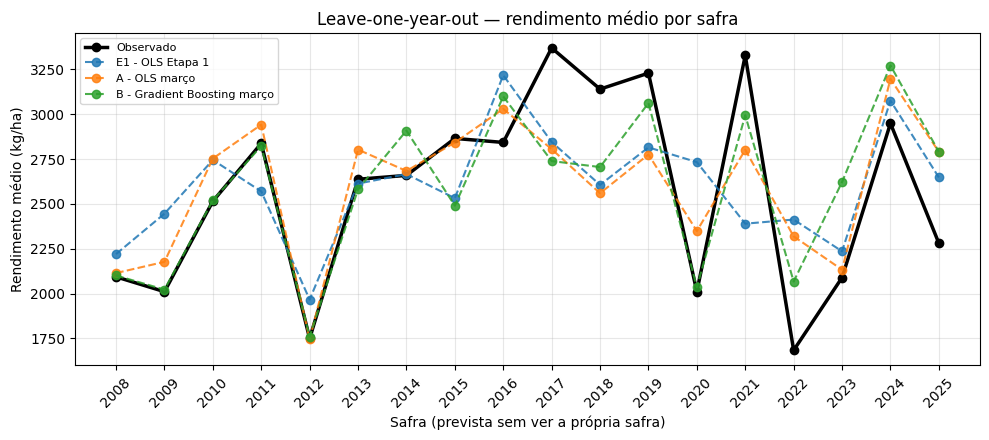

,rendimento_kg_ha,E1 - OLS Etapa 1,A - OLS março,B - Gradient Boosting março
ano_safra,,,,
2008,"2,093.00","2,220.00","2,115.00","2,101.00"
2009,"2,011.00","2,446.00","2,177.00","2,022.00"
2010,"2,515.00","2,745.00","2,753.00","2,520.00"
2011,"2,838.00","2,570.00","2,942.00","2,823.00"
2012,"1,750.00","1,967.00","1,745.00","1,761.00"
2013,"2,638.00","2,614.00","2,803.00","2,582.00"
2014,"2,659.00","2,666.00","2,684.00","2,909.00"
2015,"2,865.00","2,532.00","2,843.00","2,490.00"
2016,"2,843.00","3,218.00","3,030.00","3,100.00"


In [14]:
estado = loyo.groupby("ano_safra")[[ALVO] + LOYO].mean()
resumo_estado = pd.DataFrame({
    n: {"MAE da média estadual (kg/ha)": (estado[n] - estado[ALVO]).abs().mean(),
        "correlação com o observado": estado[n].corr(estado[ALVO])}
    for n in LOYO}).T
display(resumo_estado.round(2))

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(estado.index, estado[ALVO], "k-o", lw=2.5, label="Observado")
for nome in LOYO:
    ax.plot(estado.index, estado[nome], "--o", alpha=0.85, label=nome)
ax.set_xticks(estado.index)
ax.tick_params(axis="x", rotation=45)
ax.set_xlabel("Safra (prevista sem ver a própria safra)")
ax.set_ylabel("Rendimento médio (kg/ha)")
ax.set_title("Leave-one-year-out — rendimento médio por safra")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
estado.round(0)

## 10. Conclusões da Etapa 2 e próximos passos

**1. As novas variáveis carregam mais informação que o clima agregado.** A correlação
com o desvio do rendimento é mais forte para a umidade mínima em dez–fev (+0,52), a
chuva em dez–fev (+0,49) e os dias de calor em dez–fev (−0,47) do que para a chuva total
da safra (+0,40) e a temperatura média (−0,30). O período crítico (dez–fev) é o que
mais explica a safra, como esperado pela agronomia.

**2. Na validação "deixa uma safra de fora" (18 safras), o ganho é claro.**

| | E1 (Etapa 1) | A — OLS março | B — Gradient Boosting março |
|---|---|---|---|
| R² | 0,16 | 0,40 | **0,44** |
| RMSE (kg/ha) | 723 | 608 | **591** |
| Erro da média estadual por safra (kg/ha) | 362 | 269 | **240** |
| Correlação da média estadual com o observado | 0,55 | 0,76 | **0,80** |

Por município, o erro típico (MAE) caiu de ~580 para ~460 kg/ha (~18% do rendimento
médio). O modelo passou a acompanhar quebras e safras cheias, por exemplo 2012 (1.750
observado × 1.761 previsto pelo Gradient Boosting) e 2020 (2.011 × 2.035).

> **Nota (revisada na Etapa 3):** estes números são otimistas. Nesta validação, a
> tendência e o efeito do município são calculados com todas as outras safras, inclusive
> as posteriores à prevista, informação indisponível numa previsão real. Com o patamar
> calculado só com safras anteriores (`modelagem_etapa3.ipynb`), o R² realista é ~0,25.
> A comparação relativa entre E1, A e B continua válida (todos usam a mesma tendência).

**3. No corte 2021–2025, não houve melhora, e o motivo é o viés.** Todos os modelos
superestimam esse período (viés de +216 kg/ha na E1 a +750 kg/ha nas árvores). Duas
causas:

- **Tendência extrapolada:** a reta ajustada até 2020 projeta 3.100–3.400 kg/ha para
  2021–2025, mas a média real de 2020–2025 foi ~2.370 kg/ha (cinco de seis safras com
  seca). Os modelos partem de um patamar alto demais, e o clima não compensa
  inteiramente.
- **Árvores não extrapolam além do que viram:** 2022 e 2023 tiveram 44 e 38 dias de
  calor em dez–fev e umidade mínima de ~37%, condições mais extremas que qualquer safra
  até 2020 (máximo de 33 dias). Random Forest e Gradient Boosting "travam" a quebra no
  nível das secas do treino. A OLS extrapola e por isso sofreu menos. Na validação
  "deixa uma safra de fora" isso não acontece, porque as outras safras extremas
  recentes estão no treino.

**4. A chuva da colheita (abr–mai) não ajudou (A+, B+).** O único evento extremo na
colheita da série (enchentes de 2024) não aparece no treino, então não há como o modelo
aprender esse efeito. O **modelo de março continua sendo o principal**, e também é o
único utilizável para prever antes da colheita.

**5. O que a OLS de março diz (coeficientes):** +66 kg/ha por ano de tendência; +134
kg/ha a cada 100 mm a mais em dez–fev, com ganho decrescente (termo quadrático
negativo); +198 kg/ha a cada 100 mm em março; −18 kg/ha por dia de calor em dez–fev;
+36 kg/ha por ponto percentual de umidade mínima. Os sinais positivos de `tmax_dez_fev`
e negativos do ONI são efeito da colinearidade (a temperatura máxima se sobrepõe aos
dias de calor e o ONI à chuva), não um efeito agronômico real; por isso o conjunto
deve ser interpretado, não cada coeficiente isolado.

**Interpretação geral:** quando o patamar de produtividade (tendência) está correto, o
clima por subperíodo explica ~40–44% da variação entre municípios e safras e acompanha
bem a média estadual. O gargalo para a previsão operacional deixou de ser o clima e
passou a ser **a tendência**.

**Próximos passos:**

1. **Tratar a tendência:** testar, nas mesmas duas validações, alternativas à reta
   única de 2000–2020, como a média móvel dos últimos ~5 anos por município (o
   patamar acompanha mudanças recentes) ou tendência estimada só com anos recentes.
2. **Reduzir a colinearidade da OLS:** usar Ridge ou manter uma variável por fenômeno
   (por exemplo, chuva dez–fev, umidade mínima dez–fev e dias de calor), para os
   coeficientes ficarem interpretáveis no artigo.
3. **No artigo:** reportar as duas validações. O corte temporal mostra o desafio real
   (período 2020–2025 atípico), e o "deixa uma safra de fora" mostra o poder
   explicativo do clima.
4. **Cobertura (opcional):** a exigência de 80% dos dias com dado em cada subperíodo
   deixou 17% das linhas da Etapa 1 de fora. Uma fonte em grade (NASA POWER) poderia
   recuperá-las.